# Member C: Outcome metric

**Tasks**

- [ ] `car_av` is empty and there is no per-season AV. Decide how to handle `w_av` (career-length bias across classes): restrict window, divide by seasons possible, or use `dr_av` as a robustness check.
- [ ] AV by position: distribution, zero share, median, 90th percentile.
- [ ] Compare with `games` and `seasons_started`.
- [ ] Test contract value from `data/raw/nfl/contracts.parquet` as an alternative outcome.
- [ ] Update `src/features/outcome.py` with the final definition and post a recommendation.

See `docs/week1_tasks.md` and the project plan for details. Reusable code goes in `src/`.

In [16]:
import sys; sys.path.append('..')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.utils import *

master = pd.read_parquet(PROCESSED / 'master.parquet')
master.head()

,season,round,pick,team,gsis_id,pfr_id,cfb_player_id,player_name,hof,pos_draft,...,bench,cone,shuttle,pos_combine,has_combine,pos_group,name_clean,pick_tier,outcome,has_college_match
0,2010,1,1,STL,00-0027854,BradSa00,sam-bradford-1,Sam Bradford,False,QB,...,NaN,NaN,NaN,QB,True,QB,sam bradford,1-5,44.0,False
1,2010,1,2,DET,00-0027855,SuhxNd99,ndamukong-suh-1,Ndamukong Suh,False,DT,...,32.0,7.21,4.44,DT,True,IDL,ndamukong suh,1-5,100.0,False
2,2010,1,3,TAM,00-0027856,McCoGe99,gerald-mccoy-1,Gerald McCoy,False,DT,...,23.0,7.32,4.48,DT,True,IDL,gerald mccoy,1-5,69.0,False
3,2010,1,4,WAS,00-0027857,WillTr21,trent-williams-2,Trent Williams,False,T,...,23.0,7.64,4.63,OT,True,OT,trent williams,1-5,109.0,False
4,2010,1,5,KAN,00-0027858,BerrEr99,eric-berry-1,Eric Berry,False,DB,...,19.0,6.80,4.23,S,True,S,eric berry,1-5,50.0,False


In [10]:
##Load the Draft Data
import nflreadpy as nfl

picks = nfl.load_draft_picks().to_pandas()
print(picks.shape)
print(picks.columns.tolist())

(12927, 36)
['season', 'round', 'pick', 'team', 'gsis_id', 'pfr_player_id', 'cfb_player_id', 'pfr_player_name', 'hof', 'position', 'category', 'side', 'college', 'age', 'to', 'allpro', 'probowls', 'seasons_started', 'w_av', 'car_av', 'dr_av', 'games', 'pass_completions', 'pass_attempts', 'pass_yards', 'pass_tds', 'pass_ints', 'rush_atts', 'rush_yards', 'rush_tds', 'receptions', 'rec_yards', 'rec_tds', 'def_solo_tackles', 'def_ints', 'def_sacks']


In [3]:
##Find the AV Columns
av_cols = [c for c in picks.columns if "av" in c.lower()]
print("AV columns:", av_cols)

picks[["season", "pick", "pfr_player_name", "position"] + av_cols].head(10)

AV columns: ['w_av', 'car_av', 'dr_av']


,season,pick,pfr_player_name,position,w_av,car_av,dr_av
0,1980,1,Billy Sims,RB,58.0,None,58.0
1,1980,2,Lam Jones,WR,21.0,None,21.0
2,1980,3,Anthony Munoz,T,138.0,None,138.0
3,1980,4,Bruce Clark,DE,46.0,None,NaN
4,1980,5,Curtis Dickey,RB,37.0,None,34.0
5,1980,6,Curtis Greer,DE,38.0,None,38.0
6,1980,7,Junior Miller,TE,14.0,None,13.0
7,1980,8,Mark Haynes,DB,66.0,None,55.0
8,1980,9,Doug Martin,DE,48.0,None,48.0
9,1980,10,Jacob Green,DE,80.0,None,80.0


In [4]:
##Check the Coverage by Draft Year
picks[picks["season"].between(2010, 2022)].groupby("season")[av_cols].count()

,w_av,car_av,dr_av
season,,,
2010,237,0,219
2011,231,0,218
2012,231,0,213
2013,231,0,212
2014,228,0,210
2015,228,0,215
2016,236,0,221
2017,231,0,218
2018,240,0,224


In [8]:
# Check: why are some picks missing w_av?
# Hypothesis: missing w_av = player never played an NFL game (a bust), not missing data.

# Restrict to our eligible draft classes (2010–2022)
window = picks[picks["season"].between(2010, 2022)]

# Picks with no weighted career AV
missing = window[window["w_av"].isna()]
print(len(missing), "picks with no w_av")

# If these players also have no games recorded, they never played
print(missing["games"].describe())

# Look at a sample to sanity-check (expect mostly late-round picks)
missing[["season", "pick", "pfr_player_name", "position", "games"]].head(15)

239 picks with no w_av
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: games, dtype: float64


,season,pick,pfr_player_name,position,games
8652,2010,76,Chad Jones,DB,NaN
8728,2010,152,Otis Hudson,T,NaN
8744,2010,168,Jonathan Crompton,QB,NaN
8748,2010,172,Brent Bowden,P,NaN
8750,2010,174,Dennis Morris,RB,NaN
8757,2010,181,Dan LeFevour,QB,NaN
8776,2010,200,Charles Scott,RB,NaN
8779,2010,203,Scotty McGee,DB,NaN
8783,2010,207,Myron Rolle,DB,NaN
8788,2010,212,Chris McCoy,DE,NaN


**Finding:** 239 picks from 2010–2022 have no `w_av`, and all 239 also have no
games recorded, so these players never appeared in an NFL game.
**Decision:** treat missing `w_av` as 0 (a bust), not as missing data.

Matplotlib is building the font cache; this may take a moment.


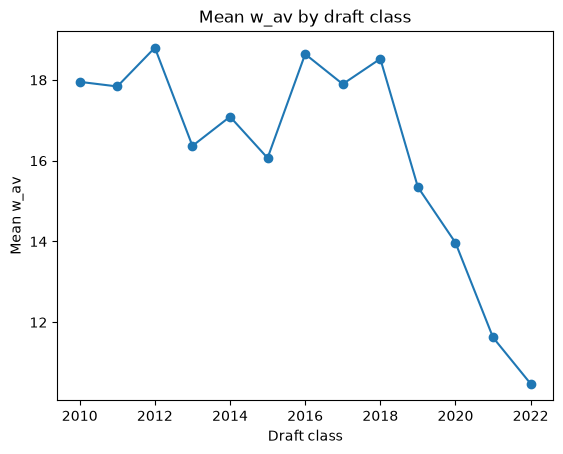

,mean,median,count
season,,,
2010,18.0,8.0,255
2011,17.8,6.0,254
2012,18.8,9.0,253
2013,16.4,9.0,254
2014,17.1,7.5,256
2015,16.1,7.0,256
2016,18.6,9.0,253
2017,17.9,9.0,253
2018,18.5,12.0,256


In [11]:
## 2. Career Length bias
import matplotlib.pyplot as plt
from src.features.outcome import add_career_length

by_class = master.groupby('season')['outcome'].agg(['mean', 'median', 'count'])
ax = by_class['mean'].plot(marker='o')
ax.set(xlabel='Draft class', ylabel='Mean w_av', title='Mean w_av by draft class')
plt.show()
by_class.round(1)

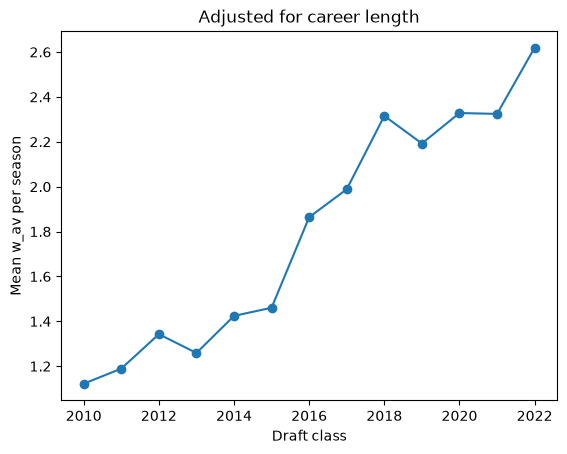

In [12]:
master = add_career_length(master)
master['w_av_per_season'] = master['outcome'] / master['seasons_possible']
ax = master.groupby('season')['w_av_per_season'].mean().plot(marker='o')
ax.set(xlabel='Draft class', ylabel='Mean w_av per season', title='Adjusted for career length')
plt.show()

**Finding:** Mean w_av is flat (~16–19) for the 2010–2018 classes, then falls
steadily for 2019–2022 (10.5 in 2022). Those players haven't finished their careers yet.
Dividing by seasons possible overcorrects (it reverses the trend) because it
counts seasons after players have retired, so we don't use it.
The median is stable (7–12) across all classes, so the drop is driven by recent
stars who are still accumulating AV.

**Decision (proposed):** outcome = w_av, restricted to 2010–2018 classes
(≥7 completed seasons). 2019–2022 can be used later as a robustness check.

In [13]:
## 3. AV by position group
# Use only mature classes (2010–2018, per Section 2) and players with a position group
mature = master[master['season'] <= 2018].copy()
print(mature['pos_group'].isna().sum(), "players with no position group (excluded)")
pos = mature.dropna(subset=['pos_group'])
print(len(pos), "players")

70 players with no position group (excluded)
2220 players


In [14]:
# Per position: sample size, median, 90th percentile, mean, share who never played (AV = 0)
summary = pos.groupby('pos_group')['outcome'].agg(
    n='count',
    median='median',
    p90=lambda s: s.quantile(0.9),
    mean='mean',
    zero_share=lambda s: (s == 0).mean(),
).reindex(POSITION_GROUPS)
summary.round(2)

,n,median,p90,mean,zero_share
pos_group,,,,,
QB,105,4.0,86.6,22.65,0.30
RB,208,7.0,42.0,14.39,0.21
WR,279,6.0,48.0,15.33,0.22
TE,138,6.0,29.3,11.22,0.25
OT,149,14.0,60.0,23.77,0.19
IOL,229,12.0,51.2,20.51,0.20
EDGE,280,14.5,59.1,23.25,0.12
IDL,166,13.5,51.0,21.11,0.12
LB,257,8.0,42.4,16.41,0.17


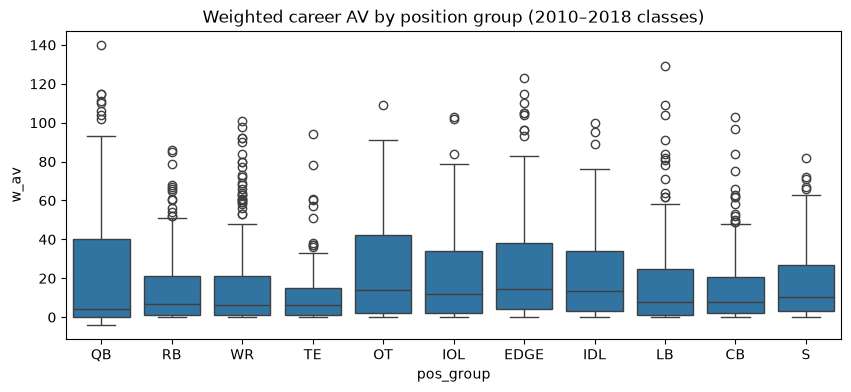

In [17]:
# Distribution of w_av by position (outliers shown as dots)
plt.figure(figsize=(10, 4))
sns.boxplot(data=pos, x='pos_group', y='outcome', order=POSITION_GROUPS)
plt.title('Weighted career AV by position group (2010–2018 classes)')
plt.ylabel('w_av')
plt.show()

### 3b. Same pick, different position: does AV favor some positions?
Raw averages mix in where positions get drafted (QBs go early). Comparing within
pick tiers controls for that.

In [18]:
# Mean w_av for each position within each pick tier, plus sample sizes
tier_mean = pos.pivot_table(index='pos_group', columns='pick_tier',
                            values='outcome', aggfunc='mean', observed=False).reindex(POSITION_GROUPS)
tier_n = pos.pivot_table(index='pos_group', columns='pick_tier',
                         values='outcome', aggfunc='count', observed=False).reindex(POSITION_GROUPS)
display(tier_mean.round(1))
display(tier_n)

pick_tier,1-5,6-15,16-32,33-64,65-100,101+
pos_group,,,,,,
QB,64.3,54.0,28.6,39.7,20.5,6.2
RB,47.0,53.8,28.4,23.4,24.7,8.2
WR,45.2,38.4,34.6,28.1,21.2,7.1
TE,NaN,29.0,23.5,26.7,16.9,6.0
OT,63.6,56.8,43.0,32.4,23.9,11.6
IOL,41.5,42.9,48.5,37.9,25.8,11.5
EDGE,60.6,57.5,38.0,29.4,26.8,12.5
IDL,61.5,54.0,31.8,23.4,18.9,13.8
LB,67.5,53.4,38.3,33.0,20.4,8.3


pick_tier,1-5,6-15,16-32,33-64,65-100,101+
pos_group,,,,,,
QB,12,8,7,9,13,56
RB,4,5,7,26,22,144
WR,5,10,16,36,43,169
TE,0,1,6,19,18,94
OT,5,10,13,21,21,79
IOL,2,7,17,23,38,142
EDGE,7,15,28,37,46,147
IDL,4,11,12,22,31,86
LB,2,7,13,37,28,170


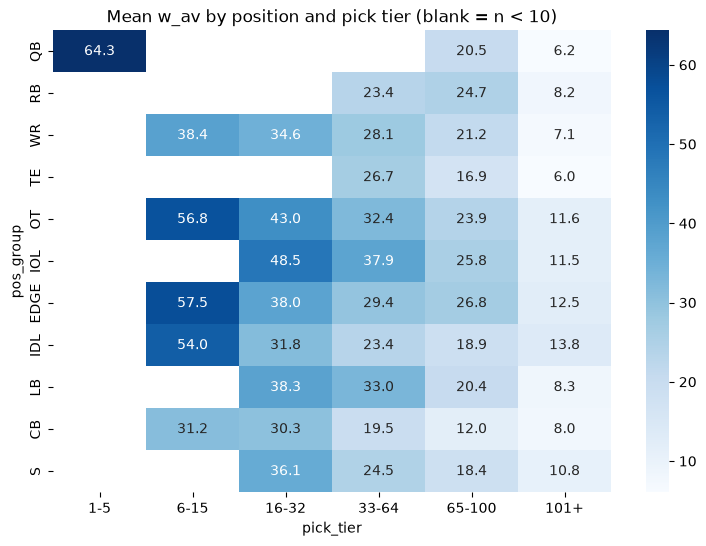

In [19]:
# Heatmap of mean w_av; cells with fewer than 10 players are hidden (too noisy)
plt.figure(figsize=(9, 6))
sns.heatmap(tier_mean.where(tier_n >= 10), annot=True, fmt='.1f', cmap='Blues')
plt.title('Mean w_av by position and pick tier (blank = n < 10)')
plt.show()

**Finding (2010–2018 classes):**
- Linemen (OT, IOL, EDGE, IDL) have the highest median w_av (~12–14); RB, WR,
  TE, LB, CB are lowest (~6–8). QB has the lowest median (~4) but the widest
  spread and highest outliers: very boom-or-bust, driven by many late-round QBs
  who never play.
- Within the same pick tier, OT and IOL are consistently at or near the top
  (e.g. 16–32: IOL 48.5, OT 43.0 vs CB 30.3), and CB is consistently near the
  bottom. QB bias can't be tested outside picks 1–5 (n < 10).
- AV can be negative (one QB below 0).

**Interpretation:** this matches the known AV bias toward offensive linemen (AV
credits starts and team success), but it could also be real value. AV alone
can't separate the two, so the contracts comparison (Section 5) is the check.

**Caveat:** many cells are small (top tiers often n < 10), so treat top-tier
differences as noisy.

In [20]:
## 4. Does w_av agree with games played and seasons started?

# Players who never played have missing games/starts: set those to 0, same as outcome
pos = pos.assign(games=pos['games'].fillna(0),
                 seasons_started=pos['seasons_started'].fillna(0))
pos[['outcome', 'games', 'seasons_started']].describe().round(1)

,outcome,games,seasons_started
count,2220.0,2220.0,2220.0
mean,18.0,63.5,2.3
std,22.3,51.7,3.1
min,-4.0,0.0,0.0
25%,1.8,19.0,0.0
50%,9.0,53.0,1.0
75%,28.0,103.0,4.0
max,140.0,249.0,15.0


In [21]:
# Spearman correlation (rank-based, so outliers don't dominate). Close to 1 = strong agreement.
pos[['outcome', 'games', 'seasons_started']].corr(method='spearman').round(2)

,outcome,games,seasons_started
outcome,1.00,0.92,0.89
games,0.92,1.00,0.82
seasons_started,0.89,0.82,1.00


In [22]:
# Does the agreement hold for every position?
corr_by_pos = pos.groupby('pos_group')[['outcome', 'games', 'seasons_started']].apply(
    lambda g: pd.Series({
        'vs_games': g['outcome'].corr(g['games'], method='spearman'),
        'vs_seasons_started': g['outcome'].corr(g['seasons_started'], method='spearman'),
        'n': len(g),
    })
).reindex(POSITION_GROUPS)
corr_by_pos.round(2)

,vs_games,vs_seasons_started,n
pos_group,,,
QB,0.96,0.89,105.0
RB,0.82,0.71,208.0
WR,0.94,0.85,279.0
TE,0.85,0.86,138.0
OT,0.97,0.94,149.0
IOL,0.96,0.95,229.0
EDGE,0.94,0.94,280.0
IDL,0.96,0.94,166.0
LB,0.94,0.91,257.0


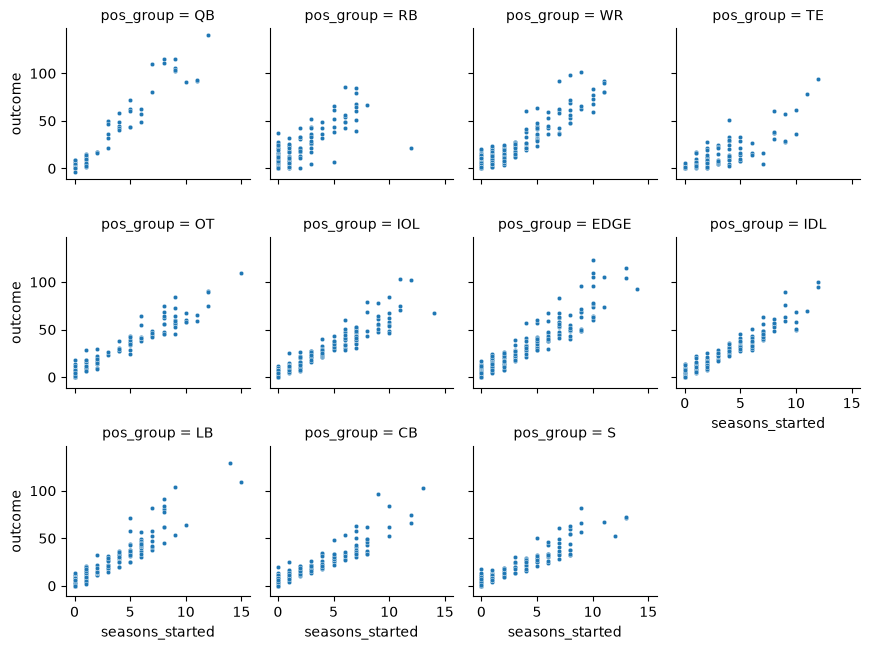

In [23]:
# w_av vs seasons started, one small plot per position
sns.relplot(data=pos, x='seasons_started', y='outcome', col='pos_group',
            col_order=POSITION_GROUPS, col_wrap=4, height=2.2, s=10)
plt.show()

In [24]:
# Among players who started at least one season: how much AV does one starting season earn?
# If OL earn more AV per starting season than CB, AV credits positions differently
# for the same role.
starters = pos[pos['seasons_started'] > 0].copy()
starters['av_per_start_season'] = starters['outcome'] / starters['seasons_started']
starters.groupby('pos_group')['av_per_start_season'].median().reindex(POSITION_GROUPS).round(2)

pos_group
QB      10.50
RB       9.50
WR       7.08
TE       4.00
OT       7.06
IOL      7.00
EDGE     8.00
IDL      6.89
LB       7.92
CB       6.73
S        6.00
Name: av_per_start_season, dtype: float64

In [25]:
# Compare each player's AV rank to his starts rank, within his position.
# Big gap = AV and starts disagree about him.
pos['av_pct'] = pos.groupby('pos_group')['outcome'].rank(pct=True)
pos['start_pct'] = pos.groupby('pos_group')['seasons_started'].rank(pct=True)
pos['gap'] = pos['av_pct'] - pos['start_pct']

cols = ['player_name', 'pos_group', 'season', 'pick', 'outcome', 'games', 'seasons_started', 'gap']
print("High AV, few starts:")
display(pos.nlargest(10, 'gap')[cols])
print("Many starts, low AV:")
display(pos.nsmallest(10, 'gap')[cols])

High AV, few starts:


,player_name,pos_group,season,pick,outcome,games,seasons_started,gap
1145,James White,RB,2014,130,37.0,95.0,0,0.581731
1348,Duke Johnson,RB,2015,77,28.0,97.0,0,0.528846
192,James Starks,RB,2010,193,26.0,76.0,0,0.514423
2137,Nyheim Hines,RB,2018,104,25.0,85.0,0,0.500000
399,Jacquizz Rodgers,RB,2011,145,24.0,110.0,0,0.487981
685,Justin Bethel,CB,2012,177,20.0,193.0,0,0.471861
2227,Russell Gage,WR,2018,194,20.0,75.0,0,0.467742
951,Rex Burkhead,RB,2013,190,21.0,115.0,0,0.463942
1945,Jamal Agnew,WR,2017,165,19.0,93.0,0,0.456989
915,Chris Thompson,RB,2013,154,20.0,74.0,0,0.439904


Many starts, low AV:


,player_name,pos_group,season,pick,outcome,games,seasons_started,gap
1226,Jay Prosch,RB,2014,211,0.0,63.0,2,-0.677885
138,John Conner,RB,2010,139,0.0,62.0,1,-0.562500
1379,Jalston Fowler,RB,2015,108,0.0,42.0,1,-0.562500
358,Luke Stocker,TE,2011,104,5.0,142.0,7,-0.438406
161,Brody Eldridge,TE,2010,162,0.0,27.0,2,-0.431159
1469,Randall Telfer,TE,2015,198,0.0,30.0,2,-0.431159
390,Anthony Sherman,RB,2011,136,5.0,153.0,3,-0.423077
494,Stanley Havili,RB,2011,240,1.0,28.0,1,-0.415865
976,Tommy Bohanon,RB,2013,215,1.0,68.0,1,-0.415865
1439,Michael Burton,RB,2015,168,1.0,155.0,1,-0.415865


**Finding:**
- w_av agrees strongly with playing time: Spearman 0.92 with games, 0.89 with
  seasons started; 0.85–0.97 for every position except RB.
- RB is weakest (0.71 vs starts). Two causes: (1) fullbacks and blocking TEs
  play many games but get ~0 AV (e.g. Jay Prosch: 63 games, 2 seasons started,
  0 AV); (2) third-down/change-of-pace backs and returners earn AV without
  being "starters".
- Median AV per starting season: QB 10.5 is highest (known QB bias); OT/IOL
  ~7.0 are mid-pack, so linemen are not credited extra per season. Their
  higher AV at the same pick (Section 3) comes from starting more seasons.
  TE (4.0) and S (6.0) earn the least per starting season.

**Implications:**
- Folding FB into RB drags RB down because AV scores fullbacks near zero.
  Recommend excluding FBs or keeping them separate (utils.py, Member A).
- AV likely undervalues blocking TEs and safeties; overvalues QBs per season.

## 5. Contracts as an alternative outcome
Idea: teams pay for performance, so a player's best second contract (after his
rookie deal) is another measure of success. We use APY as a % of the salary cap
so contracts from different years are comparable.

In [26]:
# Load the contracts table (OverTheCap via nflverse), cached by pull_all
contracts = pd.read_parquet(RAW_NFL / 'contracts.parquet')
print(contracts.shape)
print(contracts.columns.tolist())
contracts[['player', 'position', 'year_signed', 'apy', 'apy_cap_pct',
           'draft_year', 'draft_overall', 'gsis_id']].head()

(53624, 26)
['player', 'position', 'team', 'is_active', 'year_signed', 'years', 'value', 'apy', 'guaranteed', 'apy_cap_pct', 'inflated_value', 'inflated_apy', 'inflated_guaranteed', 'player_page', 'otc_id', 'gsis_id', 'height', 'weight', 'college', 'draft_year', 'draft_round', 'draft_overall', 'draft_team', 'date_of_birth', 'season_history', 'contract_history']


,player,position,year_signed,apy,apy_cap_pct,draft_year,draft_overall,gsis_id
0,Joe Burrow,QB,2023,55.000000,0.245,2020.0,1.0,00-0036442
1,Aaron Rodgers,QB,2022,50.271667,0.241,2005.0,24.0,00-0023459
2,Josh Allen,QB,2021,43.000000,0.236,2018.0,7.0,00-0034857
3,Russell Wilson,QB,2022,49.000000,0.235,2012.0,75.0,00-0029263
4,Dak Prescott,QB,2024,60.000000,0.235,2016.0,135.0,00-0033077


In [27]:
# For each player: his biggest NON-rookie contract, as % of the cap.
# Rookie deals are signed in the draft year, so keep contracts signed after it.
second = contracts[contracts['year_signed'] > contracts['draft_year']]
contract_value = (second.dropna(subset=['gsis_id'])
                        .groupby('gsis_id')['apy_cap_pct'].max()
                        .rename('contract_value'))

# Join to our players. No second contract = 0 (no team paid him after his rookie deal).
pos = pos.merge(contract_value, on='gsis_id', how='left')
pos['has_contract_row'] = pos['gsis_id'].isin(contracts['gsis_id'])
pos['contract_value'] = pos['contract_value'].fillna(0)
pos[['player_name', 'pos_group', 'outcome', 'contract_value']].sort_values(
    'contract_value', ascending=False).head(10)

,player_name,pos_group,outcome,contract_value
1977,Josh Allen,QB,111.0,0.236
560,Russell Wilson,QB,140.0,0.235
1608,Dak Prescott,QB,104.0,0.235
2002,Lamar Jackson,QB,110.0,0.231
1731,Patrick Mahomes,QB,115.0,0.227
1733,Deshaun Watson,QB,58.0,0.221
1475,Jared Goff,QB,106.0,0.208
1009,Derek Carr,QB,93.0,0.194
1971,Baker Mayfield,QB,80.0,0.183
587,Kirk Cousins,QB,102.0,0.176


In [28]:
# How many of our 2010–2018 draftees appear in the contracts data at all?
print(f"Overall: {pos['has_contract_row'].mean():.1%} of players have any contract row")
pos.groupby('pos_group')['has_contract_row'].mean().reindex(POSITION_GROUPS).round(2)

Overall: 96.9% of players have any contract row


pos_group
QB      0.91
RB      0.99
WR      0.97
TE      0.98
OT      0.95
IOL     0.95
EDGE    0.98
IDL     0.99
LB      0.96
CB      0.98
S       0.98
Name: has_contract_row, dtype: float64

In [29]:
# Spearman correlation between w_av and contract value, overall and by position
print("Overall:", round(pos['outcome'].corr(pos['contract_value'], method='spearman'), 2))
pos.groupby('pos_group')[['outcome', 'contract_value']].apply(
    lambda g: g['outcome'].corr(g['contract_value'], method='spearman')
).reindex(POSITION_GROUPS).round(2)

Overall: 0.85


pos_group
QB      0.83
RB      0.75
WR      0.85
TE      0.88
OT      0.89
IOL     0.83
EDGE    0.90
IDL     0.90
LB      0.82
CB      0.88
S       0.89
dtype: float64

,AV,Contract
pos_group,,
QB,0.86,1.46
RB,0.90,0.66
WR,0.83,0.93
TE,0.70,1.12
OT,1.19,1.14
IOL,1.23,0.94
EDGE,1.24,1.16
IDL,1.20,1.13
LB,0.95,0.89


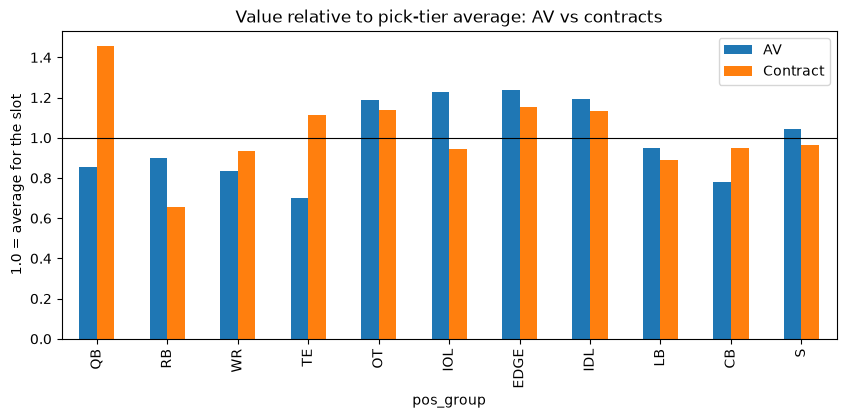

In [30]:
# For each player: his value divided by the average for his pick tier.
# 1.0 = average for that slot, above 1 = beats the slot, below 1 = lags it.
# Then average by position, for AV and for contracts side by side.
for m in ['outcome', 'contract_value']:
    tier_avg = pos.groupby('pick_tier', observed=True)[m].transform('mean')
    pos[f'{m}_vs_tier'] = pos[m] / tier_avg

compare = (pos.groupby('pos_group')[['outcome_vs_tier', 'contract_value_vs_tier']]
              .mean().reindex(POSITION_GROUPS)
              .rename(columns={'outcome_vs_tier': 'AV', 'contract_value_vs_tier': 'Contract'}))
display(compare.round(2))

compare.plot.bar(figsize=(10, 4))
plt.axhline(1, color='black', linewidth=0.8)
plt.title('Value relative to pick-tier average: AV vs contracts')
plt.ylabel('1.0 = average for the slot')
plt.show()

**Finding:**
- Coverage: 91–99% of 2010–2018 draftees appear in the contracts data
  (lowest: QB, 91%).
- Agreement with w_av: Spearman 0.85 overall; weakest for RB (0.75).
- Relative to their pick tier, OT, EDGE and IDL beat the slot on BOTH AV and
  contracts (~1.13–1.24): the most robust result.
- Contracts favor QB (0.86 → 1.46), TE (0.70 → 1.12) and CB (0.78 → 0.95)
  much more than AV does, consistent with AV undervaluing TEs (Section 4) and
  the premium QB market.
- AV favors IOL (1.23 → 0.94) and RB (0.90 → 0.66) more than contracts do:
  interior linemen and RBs play a lot but aren't paid at a premium.

**Interpretation:** the lineman advantage is real for OT, EDGE and IDL; for
IOL it depends on the metric. Conclusions about QB, TE, CB, RB and IOL change
depending on the outcome, so they should always be reported under both.

**Caveat:** contracts measure what teams pay (positional market), not just
on-field production.

## 6. Final definition and recommendation

In [31]:
# Check that the shared functions in outcome.py reproduce what this notebook found
import importlib
import src.features.outcome as outcome
importlib.reload(outcome)   # pick up the edits without restarting the notebook

test = outcome.mature_classes(master).copy()
test['contract_value'] = outcome.get_contract_outcome(test, contracts)

print(len(test), "players in 2010–2018")
print("Outcome missing:", test['outcome'].isna().sum())
print("Spearman w_av vs contract:",
      round(test['outcome'].corr(test['contract_value'], method='spearman'), 2))

2290 players in 2010–2018
Outcome missing: 0
Spearman w_av vs contract: 0.85


### Recommendation

**Outcome = `w_av` (weighted career AV), missing set to 0, using the 2010–2018
draft classes.** Implemented in `get_outcome()` and `mature_classes()` in
`src/features/outcome.py`.

**Why:** `car_av` is empty and there is no per-season AV, so `w_av` is the best
available AV field. It agrees strongly with playing time (Spearman 0.92 with
games, 0.89 with seasons started) and with contract value (0.85). Restricting
to 2010–2018 removes the career-length bias; dividing by seasons possible
overcorrected.

**Robustness check:** second-contract value (APY % of cap), via
`get_contract_outcome()`. Report position-by-tier results under both metrics.
Call a position a target only if it beats its slot on both. On that standard,
OT, EDGE and IDL hold up; QB, TE, CB, IOL and RB depend on the metric.

**Open items for the team:**
1. Change the class window to 2010–2018 (`CLASS_MAX` in `utils.py`, Member A),
   or filter with `mature_classes()`.
2. Exclude fullbacks or give them their own group: AV scores them ~0, which
   drags RB down (`POSITION_MAP` in `utils.py`, Member A).
3. Members B and E: use `get_outcome()` for the main results and repeat key
   results with `get_contract_outcome()`.